# Recommendation 02 — Popularity, Matrix Factorization e GTE content-based

**Benchmark su MovieLens con protocollo `rs_coldstart_v1`, senza ricalcolare embedding.**

- Training MF esclusivamente su `inputs/train_ratings.csv`; nuovi utenti adattati tramite **fold-in** dei rating visibili (nessun riaddestramento globale).
- **Popularity** (media Bayesian-shrinkage dei rating) come baseline indipendente dalle preferenze personali e fallback comune a `k=0`.
- **GTE diretto** mediante vettori dei **film già disponibili**, da Qdrant o da un file di embedding già calcolati; niente LLM e niente nuova inferenza GTE.
- Hyperparametri scelti sulla sola **validation**; test soltanto dopo la selezione. Metriche **A** (20 target fissi) e **B** (tutti i rating non rivelati) calcolate sugli **stessi ranking**.
- Il notebook **non importa né modifica** gli agenti, gli MCP o i workflow LLM; salva i risultati nella cartella del protocollo.

### Limite dichiarato: metadata MovieLens negli embedding preesistenti

Gli embedding già presenti potrebbero incorporare tag o statistiche aggregate anche dagli **utenti di test**, perché sono stati calcolati prima dello split degli utenti. **Il fatto che la query non contenga quei tag non elimina il problema**: essi potrebbero contribuire ai vettori dei film. Riutilizzarli è una scelta pratica per un benchmark *esplorativo*, ma **non consente di rivendicare un confronto completamente leakage-free tra MF e GTE**. Non utilizzeremo nuovi dati dei test users nei profili; conserveremo una nota esplicita sul rischio di leakage e, se servisse un risultato rigoroso, sarà necessaria una verifica con embedding costruiti soltanto da metadata TMDb.

### Modalità di esecuzione

1. Esegui il notebook 01 e conserva i CSV già esportati sotto `datasets/processed/recommendation_protocol/rs_coldstart_v1/`.
2. Configura in **cella 1** la fonte dei vettori GTE (Qdrant o NPZ); **non** usare una collezione BGE-M3 per errore.
3. Esegui tutte le celle in ordine: controlli → training → validation → scelta iperparametri → test → report.
4. Se la fonte GTE non è accessibile, il notebook **segnala esplicitamente il problema** e permette comunque di procedere con Popularity/MF, ma non presenta un confronto incompleto come definitivo.

## 0 — Parametri e percorsi

Il catalogo è quello del **protocollo già creato**, non un catalogo rigenerato. Le statistiche MovieLens aggregate nel CSV di arricchimento **non** entrano nella costruzione dei profili utente.

In [1]:
from pathlib import Path
from dataclasses import dataclass
from collections import defaultdict
import json, hashlib, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT_OVERRIDE = None  # Path('/.../progetto') se necessario
PROTOCOL_ID = "rs_coldstart_full"
SEED = 20261021
TOP_K = 10
POS_MIN = 4.0
NEG_MAX = 2.0

# Scegli come leggere embedding GTE già calcolati:
#   'qdrant': Qdrant locale/remoto; seleziona una collezione GTE con >= 1996 film
#   'npz': un file con array 'movie_ids' e 'vectors' (nessuna modifica degli embedding)
#   'off': esegue soltanto Popularity + MF, segnalando il confronto parziale.
GTE_SOURCE = 'qdrant'
GTE_NPZ = None       # Path('/.../gte_vectors_2000.npz') se GTE_SOURCE='npz'
QDRANT_URL = 'http://localhost:6333'
QDRANT_API_KEY = None  # può essere letta anche da env QDRANT_API_KEY
QDRANT_COLLECTION = 'movies_d_full_enriched_v2_gte_multilingual_base_v1'   # impostare esplicitamente il nome corretto, oppure autodiscovery univoca
QDRANT_VECTOR_NAME = None  # None se vettore senza nome, oppure 'dense'/nome vettore
QDRANT_MOVIE_ID_KEY = 'resource_id' # 'movieId'  # campo nel payload; proviamo anche 'movie_id'/'movieId_ml'
GTE_REQUIRED_COVERAGE = 1.0   # nessun confronto A/B se manca anche un film nel catalogo

# Parametri limitati, cercati sulla sola validation; modificabili prima dei test.
MF_RANK = 24
MF_EPOCHS = 18
MF_LR = 0.008
MF_REG = 0.06
MF_FOLD_REG_GRID = (1.0, 5.0, 20.0)
GTE_NEG_ALPHA_GRID = (0.2, 0.5, 0.8)
POPULARITY_PRIOR = 15.0    # shrinkage n/(n+prior)
GTE_NEG_ONLY_ALPHA = 0.35
TUNE_K_LEVELS = (1,3,5,10)
SAVE_OUTPUTS = True


def get_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    for folder in [Path.cwd(), *list(Path.cwd().resolve().parents)[:5]]:
        if (folder / 'datasets/processed/recommendation_protocol' / PROTOCOL_ID / 'protocol_manifest.json').is_file():
            return folder.resolve()
    raise FileNotFoundError('Protocollo non trovato. Copia il notebook in notebooks/ o imposta PROJECT_ROOT_OVERRIDE.')

ROOT = get_root()
BASE = ROOT / 'datasets/processed/recommendation_protocol' / PROTOCOL_ID
INPUTS = BASE / 'inputs'
PRIVATE = BASE / 'private_evaluation'
PRED = BASE / 'predictions'
REPORT = BASE / 'evaluations' / 'baseline_mf_gte'
print('Root:', ROOT)
print('Protocollo:', BASE)
print('Fonte GTE:', GTE_SOURCE)

Root: /Users/danieleraveglia/Documents/uniMi/TESI/progetto
Protocollo: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_full
Fonte GTE: qdrant


## 1 — Leggi e valida soltanto gli input pubblici del modello

`train_ratings`, `scenario_levels`, `visible_interactions` sono l'unica fonte delle informazioni per apprendere/raccomandare. I CSV sotto `private_evaluation/` verranno letti **solo per il calcolo delle metriche** a predizioni già fissate.

In [2]:
manifest = json.loads((BASE/'protocol_manifest.json').read_text(encoding='utf-8'))
assert manifest['protocol_id'] == PROTOCOL_ID
assert int(manifest['profile_size'])==10 and int(manifest['fixed_holdout_size'])==20
assert list(manifest['levels']) == [0,1,3,5,10]
assert float(manifest['positive_rating_min']) == POS_MIN

items = pd.read_csv(INPUTS/'catalog_movie_ids.csv')
train = pd.read_csv(INPUTS/'train_ratings.csv')
scenarios = pd.read_csv(INPUTS/'scenarios.csv')
levels = pd.read_csv(INPUTS/'scenario_levels.csv')
visible = pd.read_csv(INPUTS/'visible_interactions.csv')
required = {
    'items':({'movieId'},items),
    'train':({'movieId','userId','rating'},train),
    'scenarios':({'scenario_id','userId','split','rep'},scenarios),
    'levels':({'scenario_id','userId','split','rep','k'},levels),
    'visible':({'scenario_id','movieId','rating','k'},visible),
}
for name,(cols,df) in required.items():
    if not cols.issubset(df.columns):raise ValueError(f'{name}: mancano {cols-set(df.columns)}')
ids = np.sort(items.movieId.astype('int64').unique())
assert len(ids)==len(items) and len(ids)==manifest['item_universe_size']
assert set(train.movieId).issubset(set(ids))
assert set(visible.movieId).issubset(set(ids))
assert not(set(train.userId)&set(scenarios.userId))
assert levels[['scenario_id','k']].duplicated().sum()==0
assert set(levels.scenario_id)==set(scenarios.scenario_id)
assert set(levels.k)==set(manifest['levels'])
assert train[['userId','movieId']].duplicated().sum()==0
assert not visible[['scenario_id','k','movieId']].duplicated().any()
for (sid,k), sub in visible.groupby(['scenario_id','k']):
    assert len(sub)==k
for col in ('movieId','userId'):
    train[col]=train[col].astype('int64')
for df in (levels,visible): df['k']=df.k.astype(int)
idx_movie={int(m):i for i,m in enumerate(ids)}
visible_by_level={(str(sid),int(k)):g[['movieId','rating']].copy()
                  for (sid,k),g in visible.groupby(['scenario_id','k'],sort=False)}
print('Catalogo:',len(ids),'| training users:',train.userId.nunique(), '| training rating:',len(train))
print('Scenari:',scenarios.groupby('split').size().to_dict(), '| livelli:',levels.k.value_counts().sort_index().to_dict())

Catalogo: 9623 | training users: 488 | training rating: 84218
Scenari: {'test': 150, 'validation': 150} | livelli: {0: 300, 1: 300, 3: 300, 5: 300, 10: 300}


## 2 — Baseline Popularity basata sui soli rating del training

Il punteggio di un film è la sua media rating **smussata** verso la media globale; il supporto (`n_ratings`) evita di favorire troppo film con pochissimi voti. Non usa alcuna interazione degli utenti di test.

In [3]:
global_mean=float(train.rating.mean())
agg = train.groupby('movieId').rating.agg(['sum','count']).reindex(ids,fill_value=0)
popularity_scores = (agg['sum'].to_numpy(float) + POPULARITY_PRIOR * global_mean) / (agg['count'].to_numpy(float) + POPULARITY_PRIOR)
assert len(popularity_scores)==len(ids) and np.isfinite(popularity_scores).all()
print('Media globale training:',round(global_mean,3),'| Popularity prior:',POPULARITY_PRIOR)

Media globale training: 3.476 | Popularity prior: 15.0


In [4]:
print("Popularity Scores:")
print(popularity_scores)

Popularity Scores:
[3.84728626 3.42366119 3.32191971 ... 3.47731891 3.47731891 3.50856891]


In [ ]:
print("aa")

## 3 — Matrix Factorization esplicita con bias e fold-in di nuovi utenti

Alleniamo **una volta sola** `mu + user_bias + item_bias + user_vector @ item_vector` con SGD regolarizzato, esclusivamente sui rating del training. I rating restano espliciti (0,5–5): **positivi, intermedi e negativi** sono tutti utilizzati.

Per ogni scenario di un utente mai visto manteniamo fissi tutti i parametri globali e stimiamo **soltanto** `user_bias` e `user_vector` tramite ridge regression sui rating attualmente visibili; regolarizzazione del fold-in scelta sulla validation. A `k=0` usiamo lo stesso ranking Popularity del modello non personalizzato.

Questa implementazione è una baseline semplice, non un sistema industriale ottimizzato. Niente pacchetti MF neurali, niente training sui test users.

In [5]:
class ExplicitMF:
    def __init__(self, movie_ids, rank=24, epochs=18, lr=.008, reg=.06, seed=20261021):
        self.movie_ids = np.asarray(movie_ids,dtype=np.int64)
        self.index={int(i):k for k,i in enumerate(self.movie_ids)}
        self.rank,self.epochs,self.lr,self.reg,self.seed=rank,epochs,lr,reg,seed

    def fit(self, frame):
        if frame.empty:raise ValueError('Training MF vuoto')
        users=np.sort(frame.userId.unique().astype('int64'))
        uidx={int(u):i for i,u in enumerate(users)}
        u=np.array([uidx[int(x)] for x in frame.userId],dtype=np.int32)
        it=np.array([self.index[int(x)] for x in frame.movieId],dtype=np.int32)
        r=frame.rating.to_numpy(dtype=float)
        self.mu=float(np.mean(r))
        rng=np.random.default_rng(self.seed)
        self.user_bias=np.zeros(len(users),dtype=float)
        self.item_bias=np.zeros(len(self.movie_ids),dtype=float)
        self.P=rng.normal(0, .065, size=(len(users),self.rank))
        self.Q=rng.normal(0, .065, size=(len(self.movie_ids),self.rank))
        self.loss_history=[]
        for epoch in range(self.epochs):
            order=rng.permutation(len(r))
            for j in order:
                a=int(u[j]);b=int(it[j]);observed=r[j]
                pa=self.P[a].copy();qb=self.Q[b].copy()
                err=observed-(self.mu+self.user_bias[a]+self.item_bias[b]+np.dot(pa,qb))
                self.user_bias[a]+=self.lr*(err-self.reg*self.user_bias[a])
                self.item_bias[b]+=self.lr*(err-self.reg*self.item_bias[b])
                self.P[a]+=self.lr*(err*qb-self.reg*pa)
                self.Q[b]+=self.lr*(err*pa-self.reg*qb)
            if epoch==0 or epoch==self.epochs-1 or (epoch+1)%5==0:
                pred=self.mu+self.user_bias[u]+self.item_bias[it]+np.sum(self.P[u]*self.Q[it],axis=1)
                rmse=float(np.sqrt(np.mean((r-pred)**2)))
                self.loss_history.append({'epoch':epoch+1,'train_rmse':rmse})
                print(f'MF epoch {epoch+1}/{self.epochs}: train RMSE {rmse:.4f}')
        return self

    def fold_in(self, observed, fold_reg=5.0):
        if observed.empty:
            return 0.0, np.zeros(self.rank, dtype=float)
        rowidx=np.array([self.index[int(m)] for m in observed.movieId],dtype=int)
        X=np.column_stack([np.ones(len(rowidx)), self.Q[rowidx]])
        y=observed.rating.to_numpy(float)-self.mu-self.item_bias[rowidx]
        # Ridge più severa sui fattori latenti che sul bias locale, stabile con 1 rating.
        penalty=np.eye(self.rank+1)*fold_reg
        penalty[0,0]=max(.1,fold_reg*.25)
        theta=np.linalg.solve(X.T@X+penalty, X.T@y)
        return float(theta[0]),theta[1:]

    def score(self, observed,fold_reg=5.0):
        ub,uv=self.fold_in(observed,fold_reg=fold_reg)
        return self.mu+self.item_bias+ub+self.Q@uv

start=time.perf_counter()
mf=ExplicitMF(ids,rank=MF_RANK,epochs=MF_EPOCHS,lr=MF_LR,reg=MF_REG,seed=SEED).fit(train)
print('Training MF completato in',round(time.perf_counter()-start,2),'secondi')
display(pd.DataFrame(mf.loss_history))

MF epoch 1/18: train RMSE 0.9039
MF epoch 5/18: train RMSE 0.8486
MF epoch 10/18: train RMSE 0.8233
MF epoch 15/18: train RMSE 0.8031
MF epoch 18/18: train RMSE 0.7882
Training MF completato in 10.84 secondi


,epoch,train_rmse
0,1,0.903877
1,5,0.848582
2,10,0.823340
3,15,0.803098
4,18,0.788193


## 4 — Importa **vettori GTE già calcolati** (Qdrant o NPZ)

Nessuna ricostruzione delle descrizioni e nessuna chiamata a un encoder. Tutti i `movieId` del protocollo devono essere presenti. Se la collezione selezionata contiene un altro modello (per esempio BGE-M3) o solo 50 film, **interrompi la componente GTE** e scegli la fonte corretta.

Il CSV del catalogo esiste soltanto per la corrispondenza fra `movieId` ed embedding. L'eventuale presenza di tag MovieLens **dentro gli embedding** resta una limitazione scientifica, come indicato all'inizio.

In [6]:
def load_gte_npz(path):
    if path is None:raise ValueError('GTE_NPZ non impostato')
    with np.load(Path(path),allow_pickle=False) as z:
        keys=set(z.files)
        if not {'movie_ids','vectors'}.issubset(keys):
            raise ValueError(f'NPZ deve contenere movie_ids e vectors; trovati {keys}')
        return z['movie_ids'].astype('int64'),z['vectors'].astype('float32')


def load_gte_qdrant():
    import os
    try:
        from qdrant_client import QdrantClient
    except ImportError as e:
        raise ImportError('Installare qdrant-client oppure usare GTE_SOURCE=npz. Nessun embedding è ricalcolato.') from e
    kwargs={'url':QDRANT_URL, 'timeout':60}
    key=QDRANT_API_KEY or os.environ.get('QDRANT_API_KEY')
    if key:kwargs['api_key']=key
    client=QdrantClient(**kwargs)
    names=[c.name for c in client.get_collections().collections]
    collection=QDRANT_COLLECTION
    if collection is None:
        candidates=[x for x in names if 'gte' in x.lower()]
        if len(candidates)!=1:
            raise ValueError('Seleziona esplicitamente QDRANT_COLLECTION per GTE. '
                             f'Candidati GTE: {candidates}; collezioni: {names}')
        collection=candidates[0]
        print('Collection GTE autodetected:',collection)
    if collection not in names:
        raise ValueError(f'Collezione non presente: {collection}; disponibili: {names}')
    metadata=client.get_collection(collection)
    print('Qdrant collection:',collection,'| points_count:',metadata.points_count,
          '| scegli e verifica che sia il modello GTE su ~1996 film')
    offset=None;out_ids=[];out_vec=[];seen=set();batch=0
    while True:
        points,offset=client.scroll(collection_name=collection,offset=offset,limit=256,
                                    with_payload=True,with_vectors=True)
        for p in points:
            payload=p.payload or {}
            value=payload.get(QDRANT_MOVIE_ID_KEY)
            if value is None:
                value=payload.get('movie_id',payload.get('movieId_ml'))
            if value is None:
                # Fallback a id punto soltanto se è proprio un movieId intero nel catalogo
                if isinstance(p.id,(int,np.integer)) and int(p.id) in idx_movie:
                    value=p.id
                else:
                    raise ValueError(f'Impossibile determinare movieId da payload {list(payload)[:15]}; '
                                     'configura QDRANT_MOVIE_ID_KEY')
            movie=int(value)
            if movie in seen:
                raise ValueError(f'Duplicate movieId {movie}: il database potrebbe contenere più chunk per film')
            seen.add(movie)
            vec=p.vector
            if isinstance(vec,dict):
                name=QDRANT_VECTOR_NAME
                if name is None:
                    if len(vec)==1:name=next(iter(vec))
                    else:raise ValueError(f'Vettori con nomi {list(vec)}: specifica QDRANT_VECTOR_NAME')
                if name not in vec:raise ValueError(f'Vettore {name} non presente, nomi: {list(vec)}')
                vec=vec[name]
            if vec is None:raise ValueError(f'Vettore assente per film {movie}')
            out_ids.append(movie);out_vec.append(np.asarray(vec,dtype='float32'))
        batch+=1
        if offset is None:break
        if batch>1000:raise RuntimeError('Troppi batch Qdrant. Verifica la collection.')
    return np.asarray(out_ids,dtype=np.int64),np.stack(out_vec)


def prepare_gte_vectors():
    if GTE_SOURCE=='off':return None
    if GTE_SOURCE=='qdrant':got_ids,vectors=load_gte_qdrant()
    elif GTE_SOURCE=='npz':got_ids,vectors=load_gte_npz(GTE_NPZ)
    else:raise ValueError(f'GTE_SOURCE non supportato: {GTE_SOURCE}')
    if len(np.unique(got_ids))!=len(got_ids):raise ValueError('movieId duplicati negli embedding')
    if vectors.ndim!=2 or vectors.shape[0]!=len(got_ids):raise ValueError('Dimensioni vettori errate')
    if not np.isfinite(vectors).all():raise ValueError('Embedding contengono NaN/Inf')
    lookup={int(movie):j for j,movie in enumerate(got_ids)}
    present=[int(x) for x in ids if int(x) in lookup]
    coverage=len(present)/len(ids)
    print(f'Copertura GTE: {len(present)}/{len(ids)} = {coverage:.2%}; dim={vectors.shape[1]}')
    if coverage<GTE_REQUIRED_COVERAGE:
        missing=[int(x) for x in ids if int(x) not in lookup]
        raise ValueError(f'Copertura insufficiente per confronto comune. Missing ({len(missing)}): {missing[:30]}')
    ordered=vectors[[lookup[int(x)] for x in ids]].astype(np.float32)
    lengths=np.linalg.norm(ordered,axis=1)
    if np.any(lengths<=1e-12):raise ValueError('Embedding di lunghezza nulla')
    return ordered/lengths[:,None]

# Se la collection GTE non è ancora individuata, non blocchiamo l'esecuzione di MF.
gte_vectors=None
gte_error=None
try:
    gte_vectors=prepare_gte_vectors()
except Exception as exc:
    gte_error=f'{type(exc).__name__}: {exc}'
    print('ATTENZIONE: GTE NON disponibile:',gte_error)
    print('Correggere la configurazione e rieseguire questa cella per il confronto completo.')
if gte_vectors is not None:
    print('GTE pronto. Non è stato ricalcolato alcun vettore.')

Qdrant collection: movies_d_full_enriched_v2_gte_multilingual_base_v1 | points_count: 9623 | scegli e verifica che sia il modello GTE su ~1996 film
Copertura GTE: 9623/9623 = 100.00%; dim=768
GTE pronto. Non è stato ricalcolato alcun vettore.


## 5 — Scoring GTE positivo/negativo, più ranking coerente

- Profili **con almeno un film positivo**: centroide degli embedding positivi, penalità per il centroide negativo.
- Profili **con soli film negativi**: ranking di popolarità con penalità semantica; non presumiamo che la lontananza dai negativi identifichi da sola un gusto positivo.
- Profili solo intermedi o `k=0`: Popularity (nessun segnale semantico forte).
- Un film già rivelato viene **sempre escluso**, indipendentemente dal modello.

`GTE_NEG_ALPHA_GRID` è ottimizzato soltanto sui dati di validation. La formula della versione solo-negativi resta fissata per semplicità e dichiarata nel report.

In [7]:
def unit(x):
    norm=float(np.linalg.norm(x))
    return x/norm if norm>1e-9 else x*0.0

pop_z=(popularity_scores-np.mean(popularity_scores))/max(float(np.std(popularity_scores)),1e-8)

def gte_scores(observed, negative_alpha=.5):
    if gte_vectors is None:raise RuntimeError('Embedding GTE non disponibili: controlla sezione 4')
    pos=observed[observed.rating >= POS_MIN]
    neg=observed[observed.rating <= NEG_MAX]
    if len(pos):
        pids=[idx_movie[int(m)] for m in pos.movieId]
        pweights=np.maximum(pos.rating.to_numpy(float)-3.5,.1)
        v_pos=unit(np.average(gte_vectors[pids],axis=0,weights=pweights))
        sc=gte_vectors@v_pos
        if len(neg):
            nids=[idx_movie[int(m)] for m in neg.movieId]
            nweights=np.maximum(2.5-neg.rating.to_numpy(float),.1)
            v_neg=unit(np.average(gte_vectors[nids],axis=0,weights=nweights))
            sc=sc-negative_alpha*(gte_vectors@v_neg)
        return sc
    if len(neg):
        nids=[idx_movie[int(m)] for m in neg.movieId]
        nweights=np.maximum(2.5-neg.rating.to_numpy(float),.1)
        v_neg=unit(np.average(gte_vectors[nids],axis=0,weights=nweights))
        return pop_z-GTE_NEG_ONLY_ALPHA*(gte_vectors@v_neg)*3.0
    return popularity_scores


def top_k_ranking(scores, observed, k=TOP_K):
    if len(scores)!=len(ids):raise ValueError('La lunghezza dei punteggi non coincide con il catalogo')
    if not np.isfinite(scores).all():raise ValueError('Score non finiti')
    copy=np.asarray(scores,dtype=float).copy()
    for movie in observed.movieId:
        copy[idx_movie[int(movie)]]=-np.inf
    # Score decrescente; tie-break deterministico sul movieId crescente
    order=np.lexsort((ids, -copy))
    order=order[np.isfinite(copy[order])][:k]
    if len(order)<k:raise ValueError('Non ci sono abbastanza candidati')
    return ids[order],copy[order]

# smoke test puntuale del sistema di ranking
obs_test=visible_by_level[next(iter(visible_by_level))]
rr,_=top_k_ranking(popularity_scores,obs_test)
assert set(rr).isdisjoint(set(obs_test.movieId))
print('Ranking utility pronta. Film mostrati nei suggerimenti:',len(rr))

Ranking utility pronta. Film mostrati nei suggerimenti: 10


## 6 — Produci classifiche di validazione e seleziona gli iperparametri

Ogni combinazione produce una top 10 di film. Le **predizioni** non leggono mai il ground truth. Solo dopo il calcolo dei ranking verranno caricati i CSV privati per le metriche. Scegliamo l'iperparametro di MF/GTE con la media macro-utente NDCG@10 **A** sui soli livelli positivi `k∈{1,3,5,10}`.

In [8]:
def generate_rankings(split_name, mf_regs=(5.0,), neg_alphas=(0.5,), include_pop=True):
    recs=[]
    selected=levels.loc[levels.split==split_name].sort_values(['scenario_id','k'])
    tic=time.perf_counter()
    for j,r in enumerate(selected.itertuples(index=False),start=1):
        sid=str(r.scenario_id);k=int(r.k)
        obs=visible_by_level.get((sid,k),pd.DataFrame(columns=['movieId','rating']))
        assert len(obs)==k
        systems={}
        if include_pop:systems['popularity']=popularity_scores
        for reg in mf_regs:
            key=f'mf_foldreg_{float(reg):g}'
            systems[key]=popularity_scores if k==0 else mf.score(obs,fold_reg=float(reg))
        if gte_vectors is not None:
            for alpha in neg_alphas:
                key=f'gte_negalpha_{float(alpha):g}'
                systems[key]=popularity_scores if k==0 else gte_scores(obs,negative_alpha=float(alpha))
        for model_name,score_array in systems.items():
            movie_ids,scores=top_k_ranking(score_array,obs)
            for position,(movie,score) in enumerate(zip(movie_ids,scores),start=1):
                recs.append({'scenario_id':sid,'k':k,'model':model_name,'movieId':int(movie),
                             'rank':position,'score':float(score)})
        if j%300==0:
            print(f'{split_name}: {j}/{len(selected)} scenari-livello elaborati')
    result=pd.DataFrame(recs)
    print(f'{split_name}: {len(result):,} righe, {time.perf_counter()-tic:.1f}s')
    return result

val_rankings=generate_rankings('validation', mf_regs=MF_FOLD_REG_GRID,neg_alphas=GTE_NEG_ALPHA_GRID)
assert not val_rankings.empty
print('Modelli validazione:',sorted(val_rankings.model.unique()))

validation: 300/750 scenari-livello elaborati
validation: 600/750 scenari-livello elaborati
validation: 52,500 righe, 18.0s
Modelli validazione: ['gte_negalpha_0.2', 'gte_negalpha_0.5', 'gte_negalpha_0.8', 'mf_foldreg_1', 'mf_foldreg_20', 'mf_foldreg_5', 'popularity']


## 7 — Metriche A e B (solo **dopo** che i ranking sono congelati)

La **valutazione A** usa soltanto i 20 target fissi (gli item rivelati non sono in questo set); la **B** utilizza anche ulteriori rating nascosti e la parte non rivelata dei 10 rating iniziali. I film mai valutati rimangono *unjudged*, non necessariamente negativi. I ranking sono identici per A e B.

Si aggregano prima le ripetizioni per **utente**, poi si calcola la macro-media fra utenti; non trattiamo 3 repliche dello stesso utente come tre soggetti indipendenti.

In [16]:
private_scenarios=pd.read_csv(PRIVATE/'scenario_metadata.csv')
private_fixed=pd.read_csv(PRIVATE/'private_fixed_gt.csv')
private_profile=pd.read_csv(PRIVATE/'private_profile.csv')
private_extra=pd.read_csv(PRIVATE/'private_additional.csv')
for name,d in [('private_fixed',private_fixed),('private_profile',private_profile),('private_extra',private_extra)]:
    assert {'scenario_id','movieId','rating'}.issubset(d.columns),name
assert set(private_fixed.scenario_id)==set(scenarios.scenario_id)
assert private_fixed.groupby('scenario_id').size().eq(20).all()
assert private_profile.groupby('scenario_id').size().eq(10).all()
assert not set(private_profile.userId) & set(train.userId)

fixed_gt={s:dict(zip(g.movieId.astype(int),g.rating.astype(float))) for s,g in private_fixed.groupby('scenario_id')}
extra_gt={s:dict(zip(g.movieId.astype(int),g.rating.astype(float))) for s,g in private_extra.groupby('scenario_id')}
profile_rows={s:g.sort_values('reveal_order') for s,g in private_profile.groupby('scenario_id')}
level_to_owner=dict(zip(scenarios.scenario_id,scenarios.userId))
level_to_split=dict(zip(scenarios.scenario_id,scenarios.split))
valid_levels={(str(s),int(k)) for s,k in levels[['scenario_id','k']].itertuples(index=False,name=None)}


def truth_for(sid,k,scheme):
    fix=fixed_gt[sid]
    if scheme=='A':return fix
    p=profile_rows[sid]
    remaining=dict(zip(p.loc[p.reveal_order>k,'movieId'].astype(int),p.loc[p.reveal_order>k,'rating'].astype(float)))
    return {**fix,**extra_gt.get(sid,{}),**remaining}


def evaluate_rankings(predictions):
    req={'scenario_id','k','model','movieId','rank'}
    if not req.issubset(predictions):raise ValueError(f'Ranking missing: {req-set(predictions)}')
    out=[]
    for (sid,k,model),g in predictions.groupby(['scenario_id','k','model'],sort=True):
        sid=str(sid);k=int(k)
        if (sid,k) not in valid_levels:raise ValueError(f'Invalid scenario/level {(sid,k)}')
        gg=g.sort_values('rank')
        assert len(gg)>=TOP_K and gg.movieId.is_unique
        assert gg['rank'].is_unique and np.array_equal(gg['rank'].to_numpy(),np.arange(1,len(gg)+1))
        obs=visible_by_level.get((sid,k),pd.DataFrame(columns=['movieId']))
        assert not set(gg.movieId)&set(obs.movieId)
        ranked=gg.movieId.head(TOP_K).astype(int).to_numpy()
        assert set(ranked).issubset(idx_movie)
        for scheme in ('A','B'):
            truth=truth_for(sid,k,scheme)
            positives={mid for mid,rating in truth.items() if rating>=POS_MIN}
            labels=np.array([float(x in positives) for x in ranked])
            n_positive=len(positives)
            n_judged_topk=sum(x in truth for x in ranked)
            n_hits_topk=int(labels.sum())
            positive_rate_judged=(n_hits_topk/n_judged_topk) if n_judged_topk else np.nan
            if n_positive:
                discount=np.log2(np.arange(2,TOP_K+2))
                dcg=np.sum(labels/discount)
                ideal=np.sum(1/discount[:min(TOP_K,n_positive)])
                ndcg=float(dcg/ideal)
                recall=float(labels.sum()/n_positive)
                hit=float(labels.sum()>0)
            else:
                ndcg=recall=hit=np.nan
            out.append({'scenario_id':sid,'userId':int(level_to_owner[sid]),
                        'split':level_to_split[sid], 'k':k, 'model':model,'scheme':scheme,
                        'n_relevant':n_positive,'n_hits_topk':n_hits_topk,
                        'ndcg@10':ndcg,'recall@10':recall,'hr@10':hit,
                        'n_judged_topk':n_judged_topk,
                        'positive_rate_judged':positive_rate_judged,
                        'n_unjudged_topk':sum(x not in truth for x in ranked),
                        'n_A_positive_missed_by_cap_topk':sum(x not in fixed_gt[sid] and x in truth and truth[x]>=POS_MIN for x in ranked) if scheme=='B' else np.nan})
    return pd.DataFrame(out)


def summarize(per_scenario):
    metrics=['ndcg@10','recall@10','hr@10','positive_rate_judged','n_unjudged_topk','n_A_positive_missed_by_cap_topk']
    per_user=(per_scenario.groupby(['split','userId','model','scheme','k'],as_index=False)[metrics].mean())
    macro=(per_user.groupby(['split','model','scheme','k'],as_index=False)[metrics].mean())
    counts=per_user.groupby(['split','model','scheme','k'])['ndcg@10'].count().rename('n_users_with_defined_ndcg').reset_index()
    macro=macro.merge(counts,on=['split','model','scheme','k'],validate='one_to_one')
    return per_user,macro

val_metrics=evaluate_rankings(val_rankings)
val_user,val_macro=summarize(val_metrics)
assert (val_metrics.split=='validation').all()
print('Macro validation A (non ancora test):')
display(val_macro[val_macro.scheme=='A'][['model','k','ndcg@10','recall@10','hr@10','positive_rate_judged','n_users_with_defined_ndcg']].round(4))

Macro validation A (non ancora test):


,model,k,ndcg@10,recall@10,hr@10,positive_rate_judged,n_users_with_defined_ndcg
0,gte_negalpha_0.2,0,0.0657,0.0445,0.4000,0.9069,50
1,gte_negalpha_0.2,1,0.0325,0.0220,0.1867,0.8867,50
2,gte_negalpha_0.2,3,0.0327,0.0195,0.1867,0.8659,50
3,gte_negalpha_0.2,5,0.0339,0.0209,0.2067,0.8955,50
4,gte_negalpha_0.2,10,0.0380,0.0202,0.2067,0.7981,50
10,gte_negalpha_0.5,0,0.0657,0.0445,0.4000,0.9069,50
11,gte_negalpha_0.5,1,0.0325,0.0220,0.1867,0.8867,50
12,gte_negalpha_0.5,3,0.0321,0.0195,0.1867,0.8659,50
13,gte_negalpha_0.5,5,0.0321,0.0197,0.1933,0.8903,50
14,gte_negalpha_0.5,10,0.0356,0.0193,0.1933,0.8152,50


## 8 — Selezione degli iperparametri (validation soltanto)

Per MF scegliamo la regolarizzazione del fold-in, per GTE il peso dei rating negativi. A `k=0` usiamo sempre Popularity. La scelta utilizza la **media** di NDCG@10 A sui quattro livelli personalizzati, evitando tuning sui risultati di test.

In [10]:
tuning=(val_macro[(val_macro.scheme=='A') & val_macro.k.isin(TUNE_K_LEVELS)]
        .groupby('model',as_index=False)['ndcg@10'].mean().sort_values(['ndcg@10','model'],ascending=[False,True]))
display(tuning)

def choose(prefix):
    candidates=tuning[tuning.model.str.startswith(prefix)]
    if candidates.empty:return None
    return str(candidates.iloc[0].model)

chosen_mf=choose('mf_foldreg_')
chosen_gte=choose('gte_negalpha_') if gte_vectors is not None else None
assert chosen_mf is not None
selected_reg=float(chosen_mf.split('_')[-1])
selected_alpha=float(chosen_gte.split('_')[-1]) if chosen_gte else None
print('MF selezionata sulla validation:',chosen_mf)
print('GTE selezionata sulla validation:',chosen_gte or '(NON disponibile)')

,model,ndcg@10
6,popularity,0.068769
0,gte_negalpha_0.2,0.034276
1,gte_negalpha_0.5,0.033060
2,gte_negalpha_0.8,0.032103
3,mf_foldreg_1,0.020027
4,mf_foldreg_20,0.017881
5,mf_foldreg_5,0.017603


MF selezionata sulla validation: mf_foldreg_1
GTE selezionata sulla validation: gte_negalpha_0.2


## 9 — Test finale (una sola esecuzione, stessi ranking per A e B)

Selezione dei parametri conclusa. **Non** modifichiamo la scelta dopo aver visto il test. La top 10 viene calcolata sull'intero catalogo comune, escludendo soltanto i film effettivamente rivelati all'utente.

Le label dei modelli usano nomi stabili `popularity`, `mf_explicit_foldin`, `gte_direct`.

In [12]:
test_pred=generate_rankings('test',mf_regs=(selected_reg,),
                            neg_alphas=((selected_alpha,) if selected_alpha is not None else ()),
                            include_pop=True)
rename={'popularity':'popularity',chosen_mf:'mf_explicit_foldin'}
if chosen_gte:rename[chosen_gte]='gte_direct'
test_pred['model']=test_pred.model.map(rename)
assert test_pred.model.notna().all()
expected_models={'popularity','mf_explicit_foldin'}|({'gte_direct'} if chosen_gte else set())
assert set(test_pred.model)==expected_models
expected_n=len(levels[levels.split=='test'])*TOP_K*len(expected_models)
assert len(test_pred)==expected_n
print('Test rankings:',len(test_pred),'| models:',sorted(test_pred.model.unique()))
if gte_vectors is None:
    print('RISULTATO PARZIALE: GTE non disponibile! Evitare di considerare completo il confronto.')

test: 300/750 scenari-livello elaborati
test: 600/750 scenari-livello elaborati
test: 22,500 righe, 6.5s
Test rankings: 22500 | models: ['gte_direct', 'mf_explicit_foldin', 'popularity']


## 10 — Valutazione finale A/B e salvataggio

Il notebook crea `predictions/ranking_results.csv` **solo se non esiste**, per non sovrascrivere ranking di altri esperimenti. Salva comunque il proprio `rankings_baselines_test.csv` e i report dedicati. Se vuoi confrontare in futuro LLM sugli stessi utenti, il suo output potrà essere concatenato mantenendo il contratto CSV standard.

In [17]:
test_metrics=evaluate_rankings(test_pred)
test_user,test_macro=summarize(test_metrics)
assert (test_metrics.split=='test').all()
print('MACRO TEST — entrambi i protocolli:')
display(test_macro[['model','scheme','k','ndcg@10','recall@10','hr@10',
                    'positive_rate_judged','n_unjudged_topk','n_users_with_defined_ndcg']].round(4))

if SAVE_OUTPUTS:
    PRED.mkdir(parents=True,exist_ok=True)
    REPORT.mkdir(parents=True,exist_ok=True)
    own_pred=PRED/'rankings_baselines_test.csv'
    test_pred.to_csv(own_pred,index=False)
    # Non tocchiamo ranking_results.csv esistenti; i nuovi risultati restano importabili
    standard=PRED/'ranking_results.csv'
    if not standard.exists():
        test_pred.to_csv(standard,index=False)
        print('Creato:',standard)
    else:
        print('Non sovrascritto:',standard,'— il notebook 01 può essere puntato a rankings_baselines_test.csv')
    val_rankings.to_csv(PRED/'rankings_baselines_validation.csv',index=False)
    val_macro.to_csv(REPORT/'validation_macro_A_B.csv',index=False)
    test_metrics.to_csv(REPORT/'test_metrics_per_scenario_A_B.csv',index=False)
    test_user.to_csv(REPORT/'test_metrics_per_user_A_B.csv',index=False)
    test_macro.to_csv(REPORT/'test_macro_A_B.csv',index=False)
    tuning.to_csv(REPORT/'validation_hyperparameter_selection.csv',index=False)
    config={'protocol_id':PROTOCOL_ID,'seed':SEED,'source':'GTE precomputed',
            'gte_source':GTE_SOURCE,'gte_available':gte_vectors is not None,
            'gte_error':gte_error,'possible_gte_movielens_metadata_leakage':True,
            'mf_rank':MF_RANK,'mf_epochs':MF_EPOCHS,'mf_lr':MF_LR,'mf_reg':MF_REG,
            'mf_fold_reg_selected':selected_reg,'gte_neg_alpha_selected':selected_alpha,
            'popularity_prior':POPULARITY_PRIOR,'gte_negative_only_alpha':GTE_NEG_ONLY_ALPHA,
            'notes':['Solo gli utenti di training per MF/popolari',
                     'Utenti test non presenti nel training globale',
                     'A/B: stesso ranking, ground truth diverso',
                     'Unrated ≠ dislike; missing labels limitano tutte le metriche',
                     'Embedding esistenti potenzialmente contaminati da tag/statistiche MovieLens dei test users']}
    (REPORT/'model_config.json').write_text(json.dumps(config,indent=2,ensure_ascii=False),encoding='utf-8')
    print('Report:',REPORT)

MACRO TEST — entrambi i protocolli:


,model,scheme,k,ndcg@10,recall@10,hr@10,positive_rate_judged,n_unjudged_topk,n_users_with_defined_ndcg
0,gte_direct,A,0,0.0670,0.0468,0.3867,0.8784,9.4133,50
1,gte_direct,A,1,0.0315,0.0260,0.1933,0.8939,9.7333,50
2,gte_direct,A,3,0.0236,0.0228,0.1667,0.8772,9.7467,50
3,gte_direct,A,5,0.0218,0.0219,0.1733,0.8452,9.7400,50
4,gte_direct,A,10,0.0203,0.0132,0.1533,0.8026,9.7733,50
5,gte_direct,B,0,0.3023,0.0429,0.8200,0.8425,6.5200,50
6,gte_direct,B,1,0.1746,0.0224,0.5600,0.8259,7.8200,50
7,gte_direct,B,3,0.1105,0.0184,0.4667,0.7199,8.5333,50
8,gte_direct,B,5,0.0951,0.0180,0.4267,0.7953,8.7667,50
9,gte_direct,B,10,0.0889,0.0157,0.4600,0.7676,8.9933,50


Non sovrascritto: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_full/predictions/ranking_results.csv — il notebook 01 può essere puntato a rankings_baselines_test.csv
Report: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_full/evaluations/baseline_mf_gte


## 11 — Grafici e interpretazione dei risultati

Le metriche A/B vanno confrontate **all'interno** dello stesso protocollo, non prendendo la differenza assoluta di Recall A–B come misura di miglioramento. In particolare NDCG/Recall considerano non rilevanti *ai fini del calcolo* gli item non etichettati, ma questo non significa che siano film non graditi.

L'obiettivo è verificare: (1) miglioramento al crescere di `k`, (2) differenza MF/GTE sullo stesso input, (3) sensibilità dei risultati al numero di target realmente osservati.

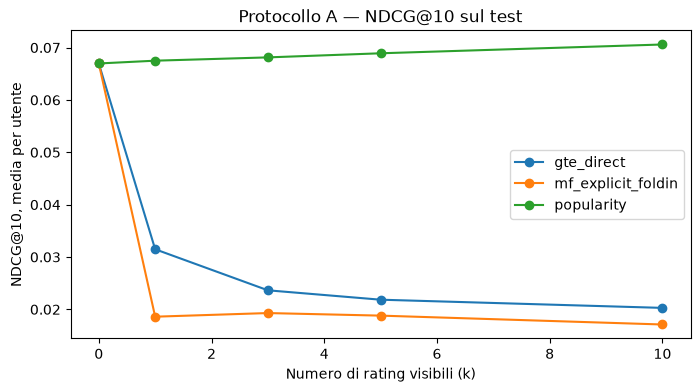

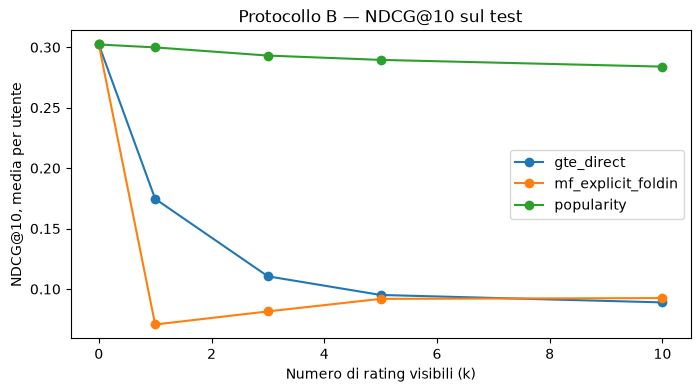

Copertura di giudizi nella top10, quota di positivi tra i giudicati e raccomandazioni positive fuori cap:


,scheme,model,k,positive_rate_judged,n_unjudged_topk,n_A_positive_missed_by_cap_topk
0,A,gte_direct,0,0.8784,9.4133,NaN
1,A,gte_direct,1,0.8939,9.7333,NaN
2,A,gte_direct,3,0.8772,9.7467,NaN
3,A,gte_direct,5,0.8452,9.7400,NaN
4,A,gte_direct,10,0.8026,9.7733,NaN
5,B,gte_direct,0,0.8425,6.5200,2.2000
6,B,gte_direct,1,0.8259,7.8200,1.3533
7,B,gte_direct,3,0.7199,8.5333,0.7800
8,B,gte_direct,5,0.7953,8.7667,0.6800
9,B,gte_direct,10,0.7676,8.9933,0.6133


In [18]:
for scheme in ('A','B'):
    sub=test_macro[test_macro.scheme==scheme]
    plt.figure(figsize=(8,4))
    for name,g in sub.groupby('model'):
        g=g.sort_values('k')
        plt.plot(g.k,g['ndcg@10'],marker='o',label=name)
    plt.xlabel('Numero di rating visibili (k)')
    plt.ylabel('NDCG@10, media per utente')
    plt.title(f'Protocollo {scheme} — NDCG@10 sul test')
    plt.legend()
    plt.show()

print('Copertura di giudizi nella top10, quota di positivi tra i giudicati e raccomandazioni positive fuori cap:')
display(test_macro[['scheme','model','k','positive_rate_judged','n_unjudged_topk','n_A_positive_missed_by_cap_topk']].round(4))

## 12 — Decisioni prima di integrare LLM/orchestratore

1. Confronto MF/GTE riuscito? Se `GTE_SOURCE` non è configurato o la collezione contiene meno di 1.996 film, sistemare **solo il caricamento dei vettori**, senza alterare protocollo/rating.
2. Per **MF** l'ottimo della regolarizzazione fold-in è scelto sulla validation, non sul test.
3. **GTE** sfrutta i vettori già calcolati. Se i documenti originali contenevano tag/statistiche MovieLens, è presente un possibile **leakage del test nei vettori** anche se la query deriva solo dai rating rivelati. Questo confronto resta esplorativo finché non viene eseguita una verifica con rappresentazioni train-independent.
4. Il risultato **A** è il confronto primario; **B** è la sensitivity analysis a costo di inferenza nullo.
5. Per il successivo LLM+GTE utilizzare gli stessi `scenario_id`, `k`, lo stesso `catalog_movie_ids.csv` e lo stesso formato di ranking, evitando di passare file `private_evaluation/` agli agenti.
6. Niente modifiche ai file `src/movie_rag`, MCP o workflow dell'orchestratore.